In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("shanegerami/ai-vs-human-text")

print("Path to dataset files:", path)

100%|██████████| 350M/350M [00:02<00:00, 125MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/shanegerami/ai-vs-human-text/versions/1


In [30]:
!pip install -q datasets
from datasets import load_dataset

wiki = load_dataset("aadityaubhat/GPT-wiki-intro", split="train[:5000]").to_pandas()
wiki_df = pd.concat([
    pd.DataFrame({"text": wiki["wiki_intro"],      "label": 0, "source": "wiki"}),   # human
    pd.DataFrame({"text": wiki["generated_intro"], "label": 1, "source": "wiki"}),   # AI
])
del wiki; gc.collect()

data["source"] = "essay"
data = pd.concat([data[["text", "label", "source"]], wiki_df])
data["n_words"] = data["text"].str.count(r"\s+") + 1
data = data[data["n_words"] >= 50].sample(frac=1, random_state=42).reset_index(drop=True)
print(data.groupby(["source", "label"]).size())

README.md:   0%|          | 0.00/2.63k [00:00<?, ?B/s]

GPT-wiki-intro.csv.zip: reconstructing file:   0%|          |  0.00B /  127MB            

GPT-wiki-intro.csv.zip: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/150000 [00:00<?, ? examples/s]

source  label
essay   0        5000
        1        5000
wiki    0        5000
        1        4692
dtype: int64


In [2]:
!pip install -q textstat xgboost

import os, re, glob, joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import nltk, textstat
from collections import Counter
from tqdm.auto import tqdm

tqdm.pandas()
for pkg in ["punkt", "punkt_tab", "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)

In [34]:
## 2 + 3. Load in chunks (memory-safe), clean, and take a balanced sample
import gc, kagglehub

path = kagglehub.dataset_download("shanegerami/ai-vs-human-text")   # cached, so it's instant
csv_file = glob.glob(os.path.join(path, "*.csv"))[0]

# Read 50k rows at a time and keep only 10% of each chunk
chunks = []
for chunk in pd.read_csv(csv_file, chunksize=50_000):
    chunk = chunk.dropna(subset=["text"])
    chunks.append(chunk.sample(frac=0.10, random_state=42))
df = pd.concat(chunks, ignore_index=True)
del chunks; gc.collect()
print("Loaded subset:", df.shape)

# Clean
df = df.drop_duplicates(subset="text")
df["label"] = df["generated"].astype(int)            # 1 = AI, 0 = Human
df["text"] = df["text"].str.strip()
df["n_words"] = df["text"].str.count(r"\s+") + 1      # word count without building lists
df = df[df["n_words"].between(100, 1000)]
print(df["label"].value_counts())

# Balanced sample
N_PER_CLASS = 5000
data = pd.concat([df[df["label"] == c].sample(N_PER_CLASS, random_state=42) for c in [0, 1]])
data = data.sample(frac=1, random_state=42).reset_index(drop=True)

del df; gc.collect()                                   # free memory, we only need `data` now
print("Final dataset:", data.shape)

Using Colab cache for faster access to the 'ai-vs-human-text' dataset.
Loaded subset: (48724, 2)
label
0    30159
1    18121
Name: count, dtype: int64
Final dataset: (10000, 4)


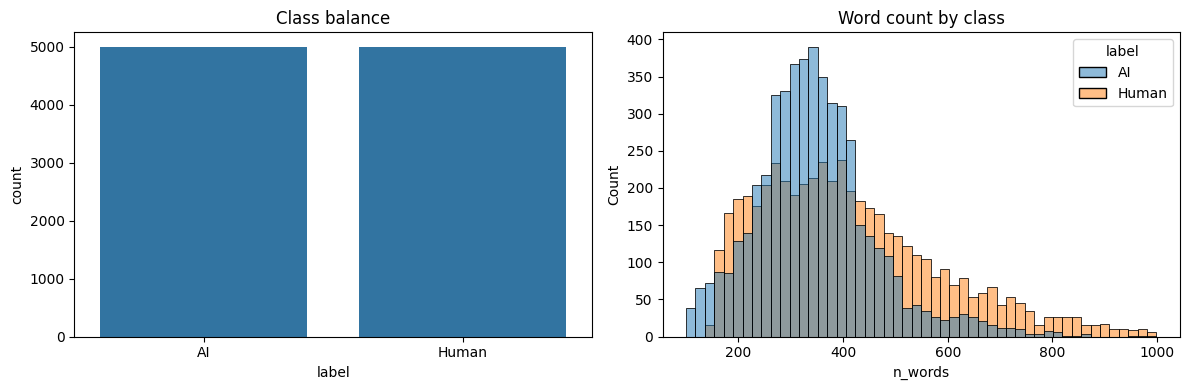

In [35]:
# ## 4. Quick EDA

# %%
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(x=data["label"].map({0: "Human", 1: "AI"}), ax=ax[0]).set_title("Class balance")
sns.histplot(data=data, x="n_words", hue=data["label"].map({0: "Human", 1: "AI"}),
             bins=50, ax=ax[1]).set_title("Word count by class")
plt.tight_layout(); plt.show()

In [36]:
## 5. NLP feature extraction
# One function turns a text into a feature vector covering all 8 feature groups:
# sentence variation, vocabulary diversity, repetition, burstiness, formality, paragraph structure, readability and POS patterns.



WORD_RE        = re.compile(r"[A-Za-z']+")
CONTRACTION_RE = re.compile(r"\b\w+(?:n't|'re|'ve|'ll|'m|'d)\b", re.I)   # possessive 's no longer counted
PASSIVE_RE     = re.compile(r"\b(?:is|are|was|were|be|been|being)\s+\w+ed\b", re.I)
FIRST_PERSON   = {"i", "me", "my", "mine", "we", "us", "our", "ours"}

def cv(values):
    values = np.asarray(values, dtype=float)
    return values.std() / values.mean() if len(values) > 1 and values.mean() > 0 else 0.0

def repeat_ratio(tokens, n):
    grams = list(zip(*[tokens[i:] for i in range(n)]))
    if not grams:
        return 0.0
    counts = Counter(grams)
    return sum(c for c in counts.values() if c > 1) / len(grams)

def extract_features(text):
    text = re.sub(r"\[\w{1,4}\]", "", text)                 # remove citation marks like [a], [12]
    text = re.sub(r"(?<!\n)\n(?!\n)", " ", text)             # single line break = wrapped line
    sentences  = nltk.sent_tokenize(text)
    words      = WORD_RE.findall(text)
    lower      = [w.lower() for w in words]
    n_words    = max(len(words), 1)
    n_sents    = max(len(sentences), 1)
    sent_lens  = [len(WORD_RE.findall(s)) for s in sentences] or [0]
    paragraphs = [p for p in re.split(r"\n\s*\n", text) if p.strip()]   # real paragraphs only
    para_lens  = [len(WORD_RE.findall(p)) for p in paragraphs]

    tags = Counter(tag[:2] for _, tag in nltk.pos_tag(words))
    pct  = lambda k: 100 * tags[k] / n_words
    noun, verb, adj, adv, pron, prep, det = (pct(k) for k in ["NN", "VB", "JJ", "RB", "PR", "IN", "DT"])

    return {
        "avg_sent_len": np.mean(sent_lens), "std_sent_len": np.std(sent_lens),
        "min_sent_len": np.min(sent_lens),  "max_sent_len": np.max(sent_lens),
        "ttr": len(set(lower[:200])) / max(len(lower[:200]), 1),
        "avg_word_len": np.mean([len(w) for w in words]) if words else 0,
        "long_word_pct": 100 * sum(len(w) >= 7 for w in words) / n_words,
        "bigram_repeat": repeat_ratio(lower, 2), "trigram_repeat": repeat_ratio(lower, 3),
        "burstiness": cv(sent_lens),
        "formality": (noun + adj + prep + det - pron - verb - adv + 100) / 2,
        "contraction_rate": 100 * len(CONTRACTION_RE.findall(text)) / n_words,
        "first_person_rate": 100 * sum(w in FIRST_PERSON for w in lower) / n_words,
        "passive_rate": 100 * len(PASSIVE_RE.findall(text)) / n_sents,
        "n_paragraphs": len(paragraphs),
        "avg_para_len": np.mean(para_lens) if para_lens else 0,
        "para_len_cv": cv(para_lens),
        "flesch_ease": textstat.flesch_reading_ease(text),
        "fk_grade": textstat.flesch_kincaid_grade(text),
        "noun_pct": noun, "verb_pct": verb, "adj_pct": adj,
        "adv_pct": adv, "pron_pct": pron, "prep_pct": prep,
        "comma_rate": text.count(",") / n_sents,
        "question_rate": text.count("?") / n_sents,
    }


In [37]:
# quick sanity check
extract_features(data["text"][0])

# %%
# Takes a few minutes for 10k texts; result is cached to CSV so you only run it once
FEAT_FILE = "features.csv"
if os.path.exists(FEAT_FILE):
    features = pd.read_csv(FEAT_FILE)
else:
    features = pd.DataFrame(data["text"].progress_apply(extract_features).tolist())
    features.to_csv(FEAT_FILE, index=False)

FEATURES = list(features.columns)
features.describe().T.round(2)


  0%|          | 0/10000 [00:00<?, ?it/s]

,count,mean,std,min,25%,50%,75%,max
avg_sent_len,10000.0,20.36,9.48,2.90,16.44,19.25,22.33,368.00
std_sent_len,10000.0,8.14,5.48,0.00,5.63,7.07,9.15,282.71
min_sent_len,10000.0,7.88,8.27,0.00,4.00,7.00,10.00,368.00
max_sent_len,10000.0,38.38,18.11,12.00,29.00,34.00,43.00,632.00
ttr,10000.0,0.55,0.07,0.24,0.51,0.55,0.60,0.82
avg_word_len,10000.0,4.71,0.50,3.54,4.35,4.64,5.02,7.88
long_word_pct,10000.0,23.28,8.27,3.13,16.92,22.22,29.06,51.25
bigram_repeat,10000.0,0.27,0.13,0.00,0.18,0.26,0.35,0.89
trigram_repeat,10000.0,0.13,0.11,0.00,0.05,0.10,0.18,0.84
burstiness,10000.0,0.40,0.13,0.00,0.31,0.38,0.47,2.04


,Human,AI,AI / Human
avg_sent_len,21.511,19.212,0.89
std_sent_len,9.663,6.627,0.69
min_sent_len,7.671,8.081,1.05
max_sent_len,43.762,33.002,0.75
ttr,0.542,0.567,1.05
avg_word_len,4.430,4.997,1.13
long_word_pct,18.440,28.127,1.53
bigram_repeat,0.248,0.293,1.18
trigram_repeat,0.095,0.165,1.73
burstiness,0.451,0.352,0.78


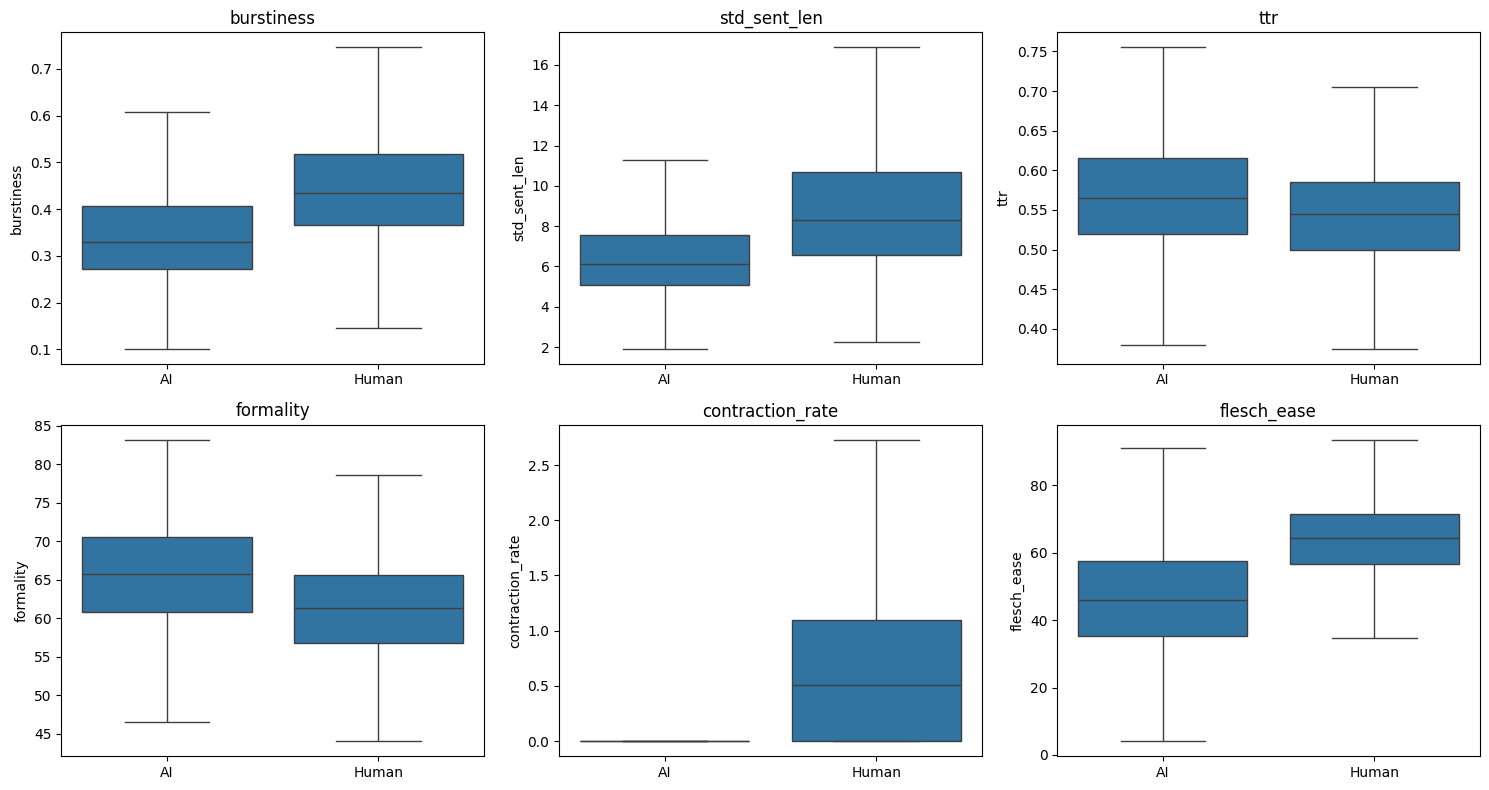

In [38]:
## 6. How do Human and AI texts differ? (writing profile)

# %%
class_means = features.groupby(data["label"]).mean().T
class_means.columns = ["Human", "AI"]
class_means["AI / Human"] = (class_means["AI"] / class_means["Human"].replace(0, np.nan)).round(2)
display(class_means.round(3))

key = ["burstiness", "std_sent_len", "ttr", "formality", "contraction_rate", "flesch_ease"]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, f in zip(axes.flat, key):
    sns.boxplot(x=data["label"].map({0: "Human", 1: "AI"}), y=features[f], ax=ax, showfliers=False)
    ax.set_title(f); ax.set_xlabel("")
plt.tight_layout(); plt.show()


In [39]:
# ## 7. Train & compare models

# %%
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, ConfusionMatrixDisplay)

X, y = features[FEATURES], data["label"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
    "Random Forest": RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=42),
    "XGBoost": XGBClassifier(n_estimators=300, max_depth=5, learning_rate=0.1,
                             eval_metric="logloss", random_state=42),
}

results = []
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    results.append({"Model": name,
                    "Accuracy": accuracy_score(y_test, pred),
                    "Precision": precision_score(y_test, pred),
                    "Recall": recall_score(y_test, pred),
                    "F1": f1_score(y_test, pred)})

results_df = pd.DataFrame(results).set_index("Model").round(4)
display(results_df)

best_name = results_df["F1"].idxmax()
best_model = models[best_name]
print("Best model:", best_name)

,Accuracy,Precision,Recall,F1
Model,,,,
Logistic Regression,0.8975,0.9044,0.889,0.8966
Random Forest,0.9485,0.9572,0.939,0.9480
XGBoost,0.9605,0.9685,0.952,0.9602


Best model: XGBoost


              precision    recall  f1-score   support

       Human       0.95      0.97      0.96      1000
          AI       0.97      0.95      0.96      1000

    accuracy                           0.96      2000
   macro avg       0.96      0.96      0.96      2000
weighted avg       0.96      0.96      0.96      2000



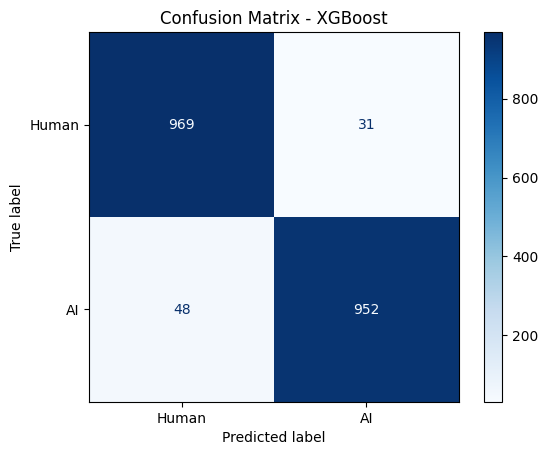

In [41]:
 #%%
pred = best_model.predict(X_test)
print(classification_report(y_test, pred, target_names=["Human", "AI"]))
ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["Human", "AI"], cmap="Blues")
plt.title(f"Confusion Matrix - {best_name}"); plt.show()

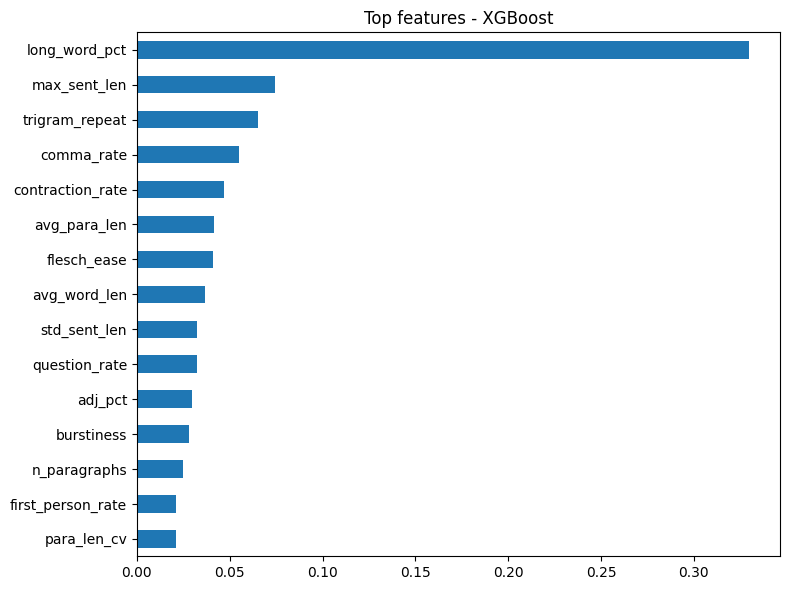

In [23]:
# ## 8. Feature importance

# %%
est = best_model[-1] if hasattr(best_model, "steps") else best_model
imp = est.feature_importances_ if hasattr(est, "feature_importances_") else np.abs(est.coef_[0])
importance = pd.Series(imp, index=FEATURES).sort_values(ascending=False)
top_features = importance.index[:8].tolist()

importance.head(15)[::-1].plot(kind="barh", figsize=(8, 6), title=f"Top features - {best_name}")
plt.tight_layout(); plt.show()

In [43]:
# ## 9. Explainable prediction for any text
# - **Level** (Low/Medium/High) = where the value falls among training texts (33rd / 66th percentile)
# - **Closer to** = whether this value is nearer the average Human or average AI text

# %%
thresholds = X_train.quantile([0.33, 0.66]).T.rename(columns={0.33: "low", 0.66: "high"})

def level(feat, value):
    t = thresholds.loc[feat]
    return "Low" if value < t["low"] else "High" if value > t["high"] else "Medium"

def analyze_text(text, model=best_model, show=True):
    f = pd.DataFrame([extract_features(text)])[FEATURES]
    p_ai = model.predict_proba(f)[0, 1]
    label = "AI-like" if p_ai >= 0.5 else "Human-like"

    rows = []
    for feat in top_features:
        v = f[feat].iloc[0]
        closer = "AI" if abs(v - class_means.loc[feat, "AI"]) < abs(v - class_means.loc[feat, "Human"]) else "Human"
        rows.append({"Feature": feat, "Value": round(v, 3), "Level": level(feat, v), "Closer to": closer})
    report = pd.DataFrame(rows)

    if show:
        print(f"Prediction: {label}   |   Confidence: {max(p_ai, 1 - p_ai):.1%}   (P(AI) = {p_ai:.2f})")
        display(report)
    return {"label": label, "prob_ai": float(p_ai), "report": report}

test_data    = data.loc[X_test.index]
sample_human = test_data[test_data.label == 0]["text"].iloc[0]
sample_ai    = test_data[test_data.label == 1]["text"].iloc[0]
_ = analyze_text(sample_human)
_ = analyze_text(sample_ai)

Prediction: Human-like   |   Confidence: 99.6%   (P(AI) = 0.00)


,Feature,Value,Level,Closer to
0,long_word_pct,17.431,Low,Human
1,max_sent_len,43.000,High,Human
2,trigram_repeat,0.086,Medium,Human
3,comma_rate,1.000,Medium,AI
4,contraction_rate,0.000,Medium,AI
5,avg_para_len,81.750,High,AI
6,flesch_ease,65.126,High,Human
7,avg_word_len,4.287,Low,Human


Prediction: AI-like   |   Confidence: 100.0%   (P(AI) = 1.00)


,Feature,Value,Level,Closer to
0,long_word_pct,25.310,Medium,AI
1,max_sent_len,28.000,Low,AI
2,trigram_repeat,0.387,High,AI
3,comma_rate,1.350,High,AI
4,contraction_rate,0.000,Medium,AI
5,avg_para_len,80.600,Medium,AI
6,flesch_ease,41.114,Low,AI
7,avg_word_len,4.953,High,AI


In [44]:
 ## 10. Compare two texts side by side

# %%
def compare_texts(text_a, text_b):
    fa, fb = extract_features(text_a), extract_features(text_b)
    table = pd.DataFrame({
        "Text A": [level(k, fa[k]) for k in top_features],
        "Text B": [level(k, fb[k]) for k in top_features],
    }, index=top_features)
    for name, t in [("Text A", text_a), ("Text B", text_b)]:
        r = analyze_text(t, show=False)
        print(f"{name}: {r['label']} (P(AI) = {r['prob_ai']:.2f})")
    return table

compare_texts(sample_human, sample_ai)


Text A: Human-like (P(AI) = 0.00)
Text B: AI-like (P(AI) = 1.00)


,Text A,Text B
long_word_pct,Low,Medium
max_sent_len,High,Low
trigram_repeat,Medium,High
comma_rate,Medium,High
contraction_rate,Medium,Medium
avg_para_len,High,Medium
flesch_ease,High,Low
avg_word_len,Low,High


In [45]:

# ## 11. Try your own text

# %%
my_text = """The deep ocean remains one of the final, unexplored frontiers on Earth. While humans have mapped the surfaces of Mars and the Moon, more than 80 percent of our own oceans remain completely unmapped and unobserved. In the twilight and midnight zones—miles below the surface—creatures survive in total darkness under crushing pressure and freezing temperatures. Instead of relying on sunlight, entire ecosystems thrive on chemical energy pouring out of hydrothermal vents. Exploring these depths is not just about discovery; studying these extreme environments helps scientists understand the origins of life and reveals how marine ecosystems regulate our global climate."""
_ = analyze_text(my_text)

Prediction: AI-like   |   Confidence: 100.0%   (P(AI) = 1.00)


,Feature,Value,Level,Closer to
0,long_word_pct,37.000,High,AI
1,max_sent_len,28.000,Low,AI
2,trigram_repeat,0.000,Low,Human
3,comma_rate,0.600,Low,Human
4,contraction_rate,0.000,Medium,AI
5,avg_para_len,100.000,High,Human
6,flesch_ease,35.483,Low,AI
7,avg_word_len,5.580,High,AI


In [49]:

my_text="""The origins of the name "Java" are not clear. Java may have been named after the jawa (foxtail millet) plant, derived from the Proto-Austronesian root *zawa.[4] The historian Michael Laffan argued that the vernacular form jawa is more likely to have derived from an older form *yaba, based on the directionality of sound changes.[5]: 10–11

In the early nineteenth century, the British scholar Stamford Raffles suggested that another possible source for Java's name is the word jauh (which he spelled jaú), a Malay word meaning "beyond" or "distant".[6] It has been suggested that another possible root is *awa or *yawa, meaning "home", related to the Polynesian words awaʻi (awaiki) or hawaʻi (hawaiki), but these roots are not universally accepted as Proto-Austronesian.[4][7] None of these alternative hypotheses has found broad support among scholars, so the jawa (millet) theory remains the generally accepted one.

The toponym Java first appears in foreign literary works around the turn of the Common Era. In Sanskrit texts like the Ramayana, Java is referred to as Yavadvīpa, with dvīpa meaning "island" and yava meaning "barley". Java is mentioned in the ancient Tamil epic Maṇimēkalai (spelled Shavakam) and also in the Pāli scripture Mahāniddesa (likely pre-1st century BCE) as a place to be reached by boats.[8][9]

The Greek term Iabadiu mentioned in Claudius Ptolemy's Geographia (150 CE), composed during the height of the Roman Empire, possibly derives from a Middle Indo-Aryan language and seems to be a synonym of the Sanskrit Yāvadvīpa. [10]

Chinese sources render the toponym Java, as 葉調 Yèdiào (Late Middle Chinese pronunciation: [jiap dɛwh]) and 耶婆提 Yépótí (Late Middle Chinese pronunciation: [jia ba dɛj]) in the early first millennium CE.[11] Subsequently, there emerged a new Chinese toponym 闍婆 Shépó (Late Middle Chinese pronunciation: [d͡ʑia bwa]), as found in the court chronicles Book of Song (late 5th century) and Book of Liang (7th century).[12] From the Yuan Dynasty (1271–1368) onwards, Java began to be called 爪哇 (Zhǎowā), the present-day name in Mandarin Chinese.[13]
"""
_ = analyze_text(my_text)

Prediction: Human-like   |   Confidence: 55.8%   (P(AI) = 0.44)


,Feature,Value,Level,Closer to
0,long_word_pct,25.872,Medium,AI
1,max_sent_len,38.000,Medium,AI
2,trigram_repeat,0.041,Low,Human
3,comma_rate,1.308,High,AI
4,contraction_rate,0.000,Medium,AI
5,avg_para_len,68.800,Medium,AI
6,flesch_ease,45.737,Low,AI
7,avg_word_len,4.628,Medium,Human


In [50]:
# ## 12. Save everything the frontend needs
# Later, copy `extract_features` (and its helpers) into a `features.py` file and load this `.joblib` in Streamlit.

# %%
artifacts = {
    "model": best_model,
    "model_name": best_name,
    "features": FEATURES,
    "top_features": top_features,
    "thresholds": thresholds,
    "class_means": class_means,
    "results": results_df,
}
joblib.dump(artifacts, "writing_analyzer.joblib")

from google.colab import files
files.download("writing_analyzer.joblib")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>